6. Object detection using Transfer Learning of CNN architectures
<br>
a. Load in a pre-trained CNN model trained on a large dataset
<br>
b. Freeze parameters (weights) in model’s lower convolutional layers
<br>
c. Add custom classifier with several layers of trainable parameters to model
<br>
d. Train classifier layers on training data available for task
<br>
e. Fine-tune hyper parameters and unfreeze more layers as needed

In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

#### Pre processing img data 

In [14]:
dataset_dir = "dataset/caltech-101/"
dataset_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
)

# here batch_size is the number of images in each batch
batch_size = 2000
dataset_generator = dataset_datagen.flow_from_directory(
    dataset_dir,
    target_size=(64, 64),
    batch_size=batch_size,
    class_mode='categorical'
)

Found 9144 images belonging to 102 classes.


#### Selecting first batch containing 2000 images as train and second batch containing 2000 images as test data

In [15]:
x_train, y_train =  dataset_generator[0]
x_test, y_test = dataset_generator[1]

print(len(x_train))
print(len(x_test))

2000
2000


#### a. Load in a pre-trained CNN model trained on a large dataset

In [16]:
# Load VGG16 without top layers
weights_path = "dataset/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"
base_model = VGG16(weights=weights_path, include_top=False, input_shape=(64, 64, 3))

E0000 00:00:1793667075.400097   37805 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793667075.413962   37805 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


#### b. Freeze parameters (weights) in model’s lower convolutional layers

In [17]:
for layer in base_model.layers:
   layer.trainable = False

#### c. Add custom classifier with several layers of trainable parameters to model

In [18]:
x = Flatten()(base_model.output)
x = Dense(64, activation='relu')(x)
predictions = Dense(102, activation='softmax')(x)

# Create the model
model = Model(inputs=base_model.input, outputs=predictions)
# Compile the model
model.compile(optimizer="adam", loss='categorical_crossentropy', metrics=['accuracy'])

#### d. Train classifier layers on training data available for task

In [19]:
# Train the model
model.fit(x_train, y_train, batch_size=64, epochs=10, validation_data=(x_test, y_test))

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 440ms/step - accuracy: 0.2195 - loss: 3.8192 - val_accuracy: 0.3280 - val_loss: 3.3929
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 17s 539ms/step - accuracy: 0.3940 - loss: 2.8828 - val_accuracy: 0.3895 - val_loss: 2.9507
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 433ms/step - accuracy: 0.4830 - loss: 2.3731 - val_accuracy: 0.4380 - val_loss: 2.6534
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 446ms/step - accuracy: 0.5655 - loss: 1.9613 - val_accuracy: 0.4860 - val_loss: 2.4044
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 436ms/step - accuracy: 0.6340 - loss: 1.6459 - val_accuracy: 0.5065 - val_loss: 2.2643
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 448ms/step - accuracy: 0.7000 - loss: 1.3902 - val_accuracy: 0.5270 - val_loss: 2.1319
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 431ms/step - accuracy: 0.7395 - loss: 1.2066 - val_accuracy: 0.5415 - val_loss: 2.0434
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 450ms/step - accuracy: 0.7815 - loss: 1.0291 - val_accu

#### e. Fine-tune hyper parameters and unfreeze more layers as needed

In [20]:
base_model = VGG16(weights=weights_path, include_top=False, input_shape=(64, 64, 3))
# freeze all layers first
for layer in base_model.layers:
   layer.trainable = False
# unfreeze last 4 layers of base model
for layer in base_model.layers[len(base_model.layers) - 2:]:
   layer.trainable = True
# fine-tuning hyper parameters
x = Flatten()(base_model.output)
x = Dense(512, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
predictions = Dense(102, activation='softmax')(x)

# Create the model
model = Model(inputs=base_model.input, outputs=predictions)
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
# training fine tuned model
model.fit(x_train, y_train, batch_size=64, epochs=10, validation_data=(x_test, y_test))

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 446ms/step - accuracy: 0.3530 - loss: 3.1333 - val_accuracy: 0.4640 - val_loss: 2.4765
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 510ms/step - accuracy: 0.5855 - loss: 1.7536 - val_accuracy: 0.5325 - val_loss: 2.0385
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 481ms/step - accuracy: 0.7105 - loss: 1.1218 - val_accuracy: 0.5820 - val_loss: 1.8463
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 498ms/step - accuracy: 0.7990 - loss: 0.7235 - val_accuracy: 0.5750 - val_loss: 1.8776
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 470ms/step - accuracy: 0.8710 - loss: 0.4394 - val_accuracy: 0.6170 - val_loss: 1.7479
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 505ms/step - accuracy: 0.9270 - loss: 0.2452 - val_accuracy: 0.6185 - val_loss: 1.8283
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 463ms/step - accuracy: 0.9635 - loss: 0.1499 - val_accuracy: 0.6195 - val_loss: 1.8914
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 499ms/step - accuracy: 0.9730 - loss: 0.1052 - val_accu

In [21]:
import matplotlib.pyplot as plt
predicted_value = model.predict(x_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step


In [22]:
labels = list(dataset_generator.class_indices.keys())

Preditcted:  hawksbill
Actual:  cougar_body


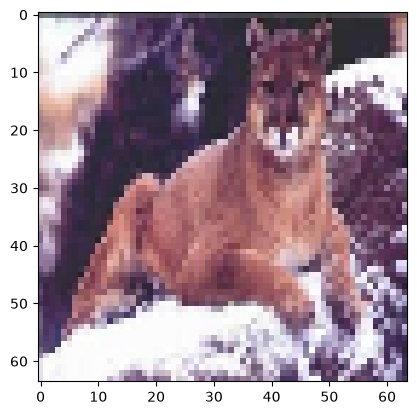

In [23]:
n = 1000
plt.imshow(x_test[n])
print("Preditcted: ",labels[np.argmax(predicted_value[n])])
print("Actual: ", labels[np.argmax(y_test[n])])